# 03 · Visualising the network in Cytoscape with py4cytoscape

This notebook drives **Cytoscape desktop** from Python through its REST API (CyREST) with
[`py4cytoscape`](https://py4cytoscape.readthedocs.io). Every view is reproducible: the visual style is defined in
code (`src/cytoscape_viz.py`) and node positions come from a deterministic layout.

**Requirements:** Cytoscape 3.10 or newer, open (CyREST listens on port 1234 by default), and the analysis
results in `results/` (`python src/pipeline.py --no-cytoscape` is enough).

The full pipeline (`python src/pipeline.py`) runs the same steps and saves the session to
`cytoscape/alzheimer_network.cys`.

In [1]:
import sys
import tempfile
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import networkx as nx
import pandas as pd
import py4cytoscape as p4c
from IPython.display import Image, display

from src import cytoscape_viz as cy
from src.config import load_config

pd.set_option("display.max_colwidth", 60)
config = load_config(ROOT / "config" / "config.yaml")
OUT = Path(tempfile.mkdtemp(prefix="cytoscape_nb_"))

assert cy.cytoscape_available(), "Start Cytoscape first"
p4c.cytoscape_version_info()

You are connected to Cytoscape!


{'apiVersion': 'v1',
 'cytoscapeVersion': '3.10.3',
 'automationAPIVersion': '1.13.0',
 'py4cytoscapeVersion': '1.13.0'}

## 1. Load the analysed network

The node table holds everything the style needs: gene symbol, seed/DIAMOnD role, cluster, centralities,
hub/bottleneck class and drug-target status.

In [2]:
tables = ROOT / "results" / "tables"
metrics = pd.read_csv(tables / "node_metrics.tsv", sep="\t", dtype={"id": str})
edge_table = pd.read_csv(tables / "ad_network_edges.tsv", sep="\t", dtype={"source": str, "target": str})

graph = nx.from_pandas_edgelist(edge_table, "source", "target", edge_attr="edge_type")
for row in metrics.to_dict(orient="records"):
    graph.nodes[row["id"]].update({k: v for k, v in row.items() if k != "id"})
labels = dict(zip(metrics["id"], metrics["cluster"]))
names = {int(k): v for k, v in config["cluster_names"].items()}

nodes, edges = cy.cytoscape_tables(graph, metrics, names)
print(f"{len(nodes)} proteins, {len(edges)} interactions")
nodes[["symbol", "role", "cluster_name", "centrality_class", "drug_status", "label"]].head()

190 proteins, 1085 interactions


,symbol,role,cluster_name,centrality_class,drug_status,label
0,BCL2L10,diamond,2. Apoptosis & neuronal death,peripheral,none,
1,BAX,seed,2. Apoptosis & neuronal death,peripheral,none,
2,BCL2L11,diamond,2. Apoptosis & neuronal death,peripheral,none,
3,GNB2L1,diamond,3. Translation & protein folding,hub non-bottleneck,none,GNB2L1
4,AKT1,seed,2. Apoptosis & neuronal death,non-hub bottleneck,druggable,AKT1


Applying default style...
Applying preferred layout


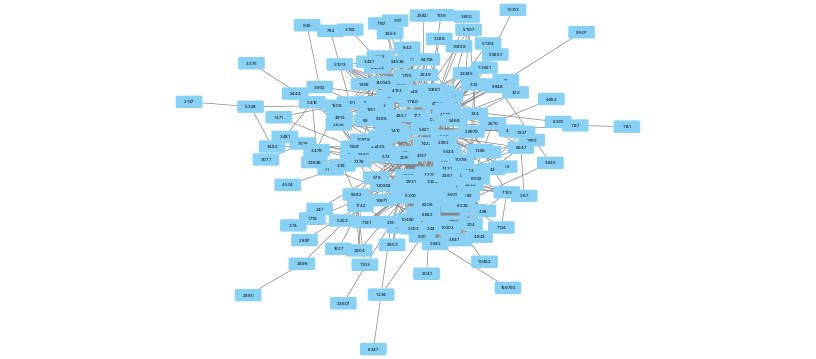

In [3]:
p4c.close_session(save_before_closing=False)
network = cy.load_network(nodes, edges, "Alzheimer's disease network", "Alzheimer's disease PPI")
p4c.layout_network("force-directed", network=network)
p4c.export_image(str(OUT / "default.png"), type="PNG", zoom=100, network=network, overwrite_file=True)
display(Image(filename=str(OUT / "default.png"), width=700))

This is Cytoscape's default rendering: every protein looks the same, and the labels are Entrez IDs.

## 2. Apply the visual style

The style maps data columns to visual properties:

In [4]:
defaults, mappings = cy.build_style(sorted(set(labels.values())), metrics["betweenness"].quantile(0.98))
pd.DataFrame([{"visual property": m["visualProperty"], "mapping": m["mappingType"], "column": m["mappingColumn"]}
              for m in mappings])

,visual property,mapping,column
0,NODE_FILL_COLOR,discrete,cluster
1,NODE_SHAPE,discrete,role
2,NODE_SIZE,continuous,betweenness
3,NODE_BORDER_PAINT,discrete,drug_status
4,NODE_BORDER_WIDTH,discrete,drug_status
5,NODE_LABEL,passthrough,label
6,NODE_TOOLTIP,passthrough,tooltip
7,EDGE_TRANSPARENCY,discrete,edge_type
8,EDGE_STROKE_UNSELECTED_PAINT,discrete,edge_type


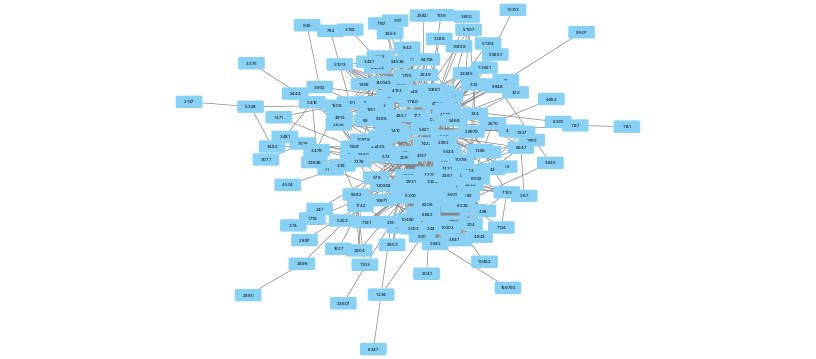

In [5]:
cy.apply_style(network, sorted(set(labels.values())), metrics["betweenness"].quantile(0.98))
p4c.export_image(str(OUT / "styled_force.png"), type="PNG", zoom=100, network=network, overwrite_file=True)
display(Image(filename=str(OUT / "styled_force.png"), width=700))

## 3. Cluster layout and legend

The force-directed layout mixes the clusters. `clustered_layout` places each Louvain cluster in its own disc
(Kamada-Kawai inside each cluster) and is deterministic. The legend is drawn with Cytoscape annotations, so it is
saved in the session and exported with the image.

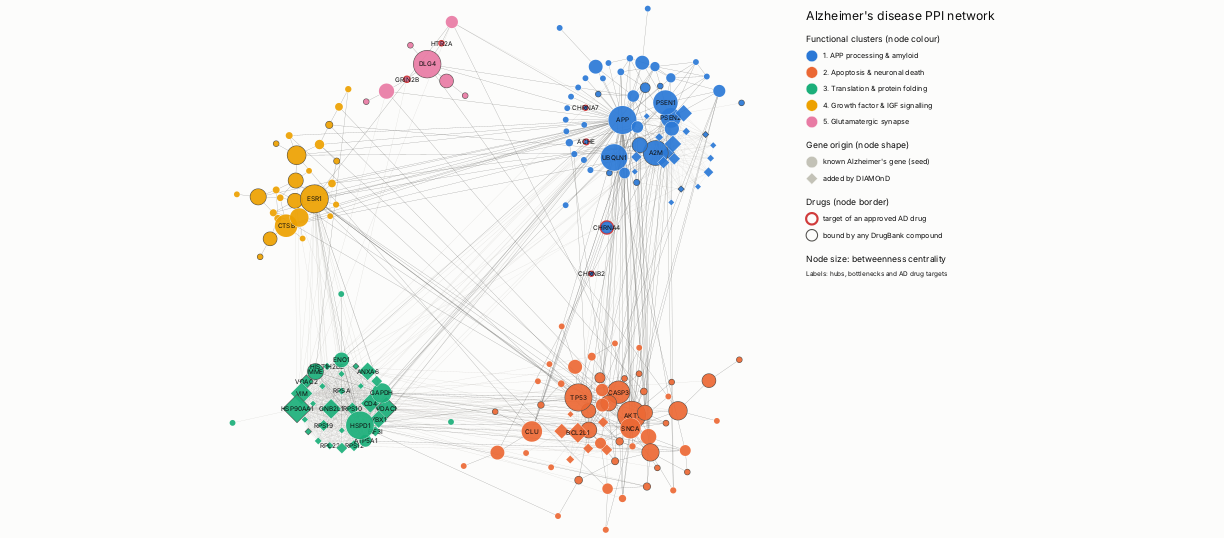

In [6]:
positions = cy.clustered_layout(graph, labels)
cy.apply_positions(positions, network)
cy.add_legend(network, positions, names)
cy.export_view(network, OUT / "alzheimer_network", formats=("PNG",), zoom=150)
display(Image(filename=str(OUT / "alzheimer_network.png"), width=950))

How to read it:

* **APP** (cluster 1, blue) is the largest node: the main bottleneck. Its partners include the secretase
  machinery (PSEN1/2, NCSTN, APH1A, BACE1) and APOE.
* The **apoptosis** cluster (orange) is centred on AKT1, TP53, CASP3 and the BCL-2 family.
* The green block is the dense **translation & protein folding** cluster, mostly DIAMOnD proteins (diamonds)
  around HSP90AA1 and HSPD1.
* Red rings mark targets of approved AD drugs (ACHE, nicotinic receptors, GRIN2B, HTR2A). All are small,
  peripheral nodes.

## 4. Zoom into a cluster

`create_subnetwork` copies the selected proteins and their interactions into a new network that keeps the
style. Here every node is labelled.

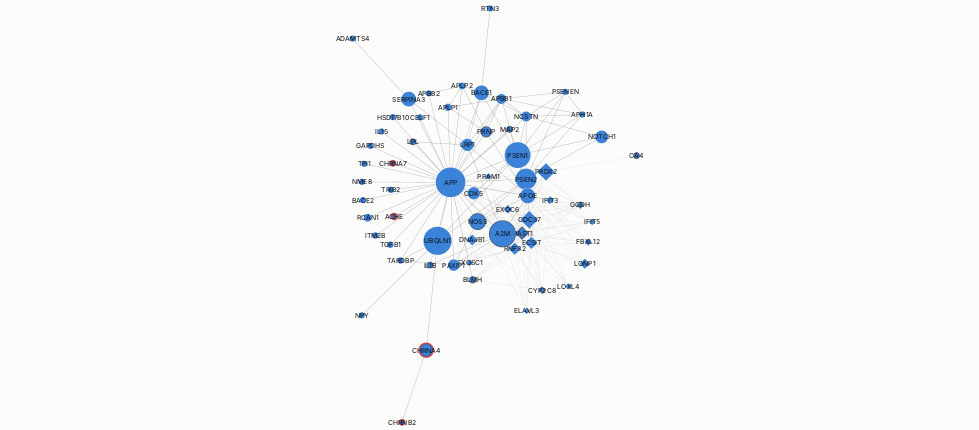

In [7]:
cluster = 1
members = [n for n, c in labels.items() if c == cluster]
sub = cy.create_subnetwork(network, members, f"Cluster {cluster}: {names[cluster]}", graph, labels)
cy.show_all_labels(sub, nodes[nodes["id"].isin(members)])
cy.export_view(sub, OUT / "cluster_1", formats=("PNG",), zoom=120)
display(Image(filename=str(OUT / "cluster_1.png"), width=900))

## 5. The neighbourhood of a drug target

The first neighbours of acetylcholinesterase (ACHE), the target of three of the four approved AD drugs, show
how loosely it is connected to the disease module.

ACHE partners: APP, GNB2L1, ENO1


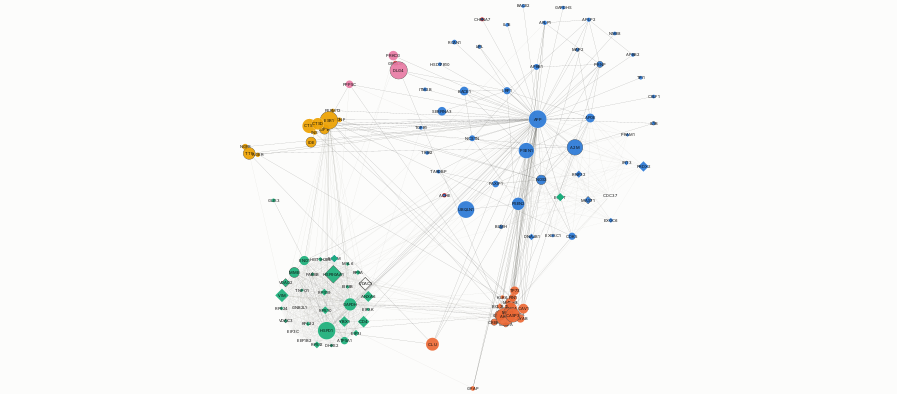

In [8]:
ache = metrics.loc[metrics["symbol"] == "ACHE", "id"].item()
neighbourhood = [ache] + list(graph.neighbors(ache))
second = sorted({m for n in neighbourhood for m in graph.neighbors(n)} | set(neighbourhood))
sub = cy.create_subnetwork(network, second, "ACHE two-step neighbourhood", graph, labels)
cy.show_all_labels(sub, nodes[nodes["id"].isin(second)])
cy.export_view(sub, OUT / "ache", formats=("PNG",), zoom=110)
print("ACHE partners:", ", ".join(metrics.set_index("id").loc[list(graph.neighbors(ache)), "symbol"]))
display(Image(filename=str(OUT / "ache.png"), width=900))

ACHE has only three partners in the AD network (APP, ENO1 and GNB2L1), so it reaches the module mainly
through APP. Its two-step neighbourhood is dominated by APP's partners, which shows again that the approved drugs act at
the edge of the network.

## 6. Save and share

* `p4c.save_session(...)` writes a `.cys` file that opens in Cytoscape with all networks, styles, layouts and
  annotations (`cytoscape/alzheimer_network.cys` in this repository).
* `p4c.export_visual_styles(...)` writes the style as XML. Load it in any Cytoscape with *File > Import >
  Styles from File*.
* Without Cytoscape, `cytoscape/network/alzheimer_network.cyjs` (with positions) and `.graphml` can be imported
  later with *File > Import > Network from File*.

In [9]:
style_xml = cy.export_style_xml(OUT / "alzheimer_style.xml")
session = cy.save_session(OUT / "notebook_session.cys")
print(style_xml.name, f"{style_xml.stat().st_size / 1e3:.0f} kB")
print(session.name, f"{session.stat().st_size / 1e3:.0f} kB")
p4c.get_network_list()

alzheimer_style.xml 12 kB
notebook_session.cys 119 kB


["Alzheimer's disease network",
 'ACHE two-step neighbourhood',
 'Cluster 1: APP processing & amyloid']